Total rows: 33,475,032 | daily precipitation rows: 1,850,932
Estat
Representatiu       1850918
No representatiu         14
Name: count, dtype: int64
1988-09-01 -> 2026-11-14 | 243 stations
Stations in catchment: 96
Included: ['Embassament de Sant Ponç (Clariana de Cardener)', 'Embassament de Sau (Vilanova de Sau)', 'Embassament de Susqueda (Osor)', 'Embassament de la Baells (Cercs)', 'Embassament de la Llosa del Cavall (Navès)'] 
Excluded: ['Embassament de Darnius Boadella (Darnius)', 'Embassament de Foix (Castellet i la Gornal)', 'Embassament de Riudecanyes', 'Embassament de Siurana (Cornudella de Montsant)']
Dimensions: (8677, 9)


,DATA_CANVI_ESTAT_SEQUERA,CODI_UNITAT_EXPLOTACI,UNITAT_EXPLOTACI,CODI_ESTAT_SEQUERA_HIDROL,ESTAT_SEQUERA_HIDROL_GIC,CODI_ESTAT_SEQUERA_PLUVIOM,ESTAT_SEQUERA_PLUVIOM_TRIC,CODI_MUNICIPI,MUNICIPI
0,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170010,Agullana
1,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170118,"Armentera, l'"
2,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170427,Capmany
3,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170643,Espolla
4,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170773,Garriguella


Using -> {'date': 'DATA_CANVI_ESTAT_SEQUERA', 'unit': 'UNITAT_EXPLOTACI', 'hydrological': 'ESTAT_SEQUERA_HIDROL_GIC', 'pluviometric': 'ESTAT_SEQUERA_PLUVIOM_TRIC'}
Hydrological values : <ArrowStringArray>
[     'NORMALITAT',          'ALERTA',       'PREALERTA', 'EXCEPCIONALITAT',
      'EMERGÈNCIA',    'EMERGÈNCIA I',   'EMERGÈNCIA II',   'PREEMERGÈNCIA']
Length: 8, dtype: str
Pluviometric values : <ArrowStringArray>
['NORMALITAT', 'SEQUERA SEVERA', 'SEQUERA EXTREMA']
Length: 3, dtype: str
Official series: 2021-01 -> 2026-11


,spi6,res,hyd,plu
month,,,,
2026-06-01,0.710891,92.523616,0.0,0.0
2026-07-01,-0.639575,87.036281,0.0,0.0
2026-08-01,-0.681915,80.902853,0.0,0.0
2026-09-01,-0.961469,76.325014,0.0,0.0
2026-10-01,0.582508,75.943038,0.0,0.0


,Dry onset,Min SPI-6,Duration [m],Reservoir % at onset,Min reservoir %,Reservoirs <40% [m],Official rain: severe [m],Official hydro: alert [m],Official hydro: exceptionality [m],Official hydro: emergency [m]
0,2006-06,-2.21,23,80.1,21.2,15.0,NaN,NaN,NaN,NaN
1,2016-01,-1.38,12,73.1,55.0,NaN,NaN,NaN,NaN,NaN
2,2017-09,-1.58,6,61.8,45.4,NaN,NaN,NaN,NaN,NaN
3,2019-05,-1.58,7,85.6,57.6,NaN,NaN,NaN,NaN,NaN
4,2021-05,-1.88,36,92.0,15.5,16.0,5.0,18.0,22.0,33.0


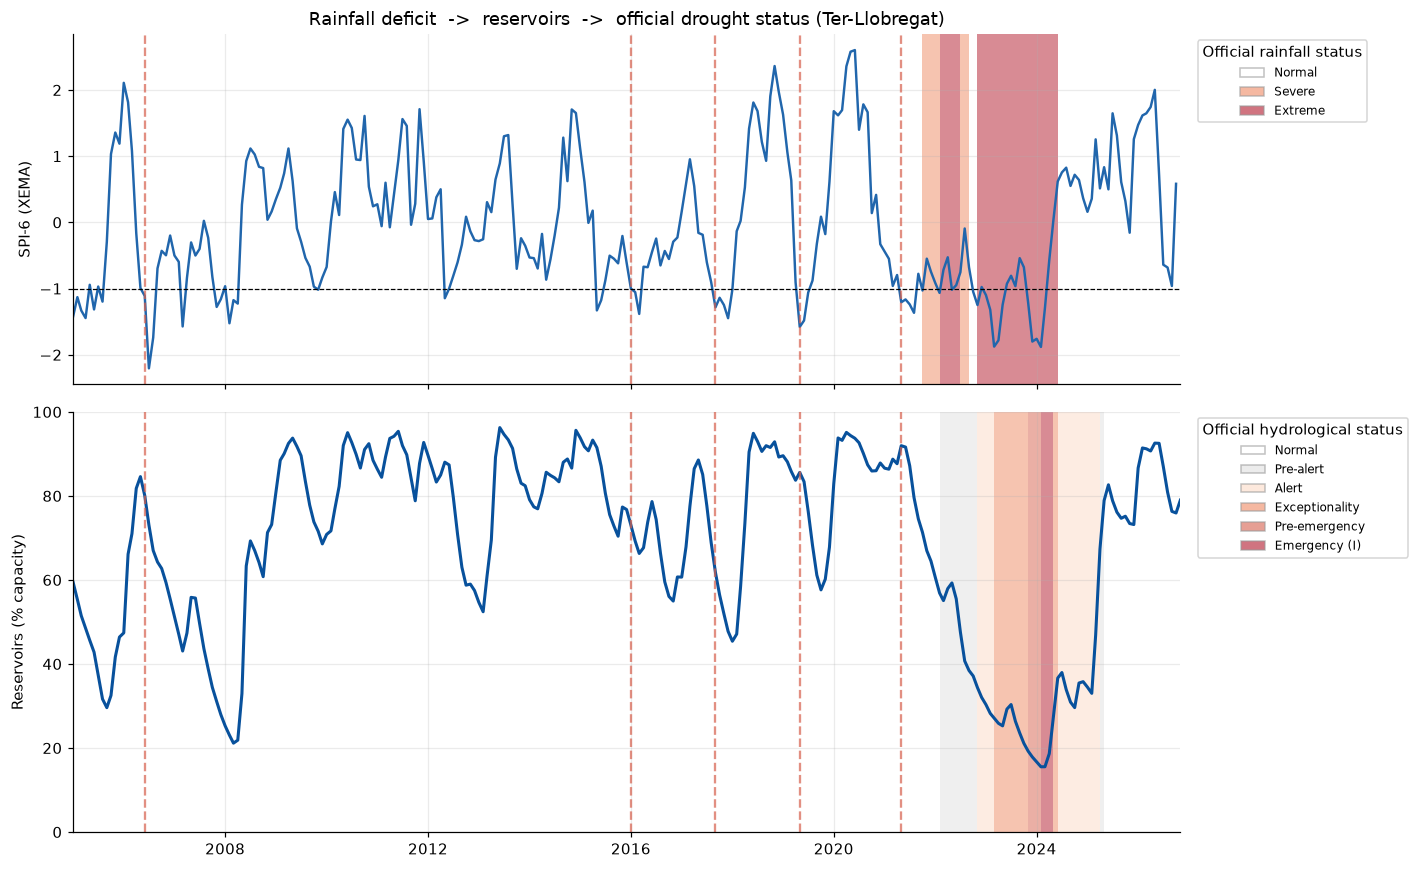

In [9]:
# # Water block: dry episode -> reservoirs -> official drought status (Catalonia)
# **Question:** how many months pass between a rainfall deficit (XEMA) and its reflection in the reservoirs (ACA)
# and in the official drought status (ACA)?
# Output: one figure, one episode table, and a monthly CSV that other blocks (fires, heat) can reuse.

# %% 0. Setup
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

SOCRATA = "https://analisi.transparenciacatalunya.cat/resource/{}.csv?$limit=1000000"
load = lambda ds: pd.read_csv(SOCRATA.format(ds), low_memory=False).rename(columns=str.upper)

def pick(df, *names):
    for n in names:
        if n in df.columns:
            return n
    raise KeyError(f"None of {names} found. Columns: {list(df.columns)}")

def find(df, rx):
    """First column matching regex, ignoring code columns (we want names)."""
    cols = [c for c in df.columns if re.search(rx, c, re.I) and "CODI" not in c.upper()]
    if not cols:
        raise KeyError(f"No column matches '{rx}'. Columns: {list(df.columns)}")
    return cols[0]

def months_between(a, b):
    return (b.year - a.year) * 12 + b.month - a.month

UNIT_KEY = "terllobregat"    # matched ignoring spaces/hyphens (unit "Embassament Ter- Llobregat"); reference exploitation unit (Barcelona area; matches the reservoir system)
# Comarques draining to the Internal Basins (edit if your team defines the catchment differently)
CATCHMENT = ["Ripollès", "Osona", "Berguedà", "Bages", "Garrotxa", "Selva", "Gironès", "Anoia", "Moianès",
             "Vallès Occidental", "Vallès Oriental", "Maresme", "Baix Llobregat", "Alt Penedès", "Garraf",
             "Barcelonès", "Alt Empordà", "Baix Empordà", "Pla de l'Estany", "Solsonès"]

# %% 1. XEMA daily -> monthly regional SPI-6
path_xema = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"
PPT_NAME = "Precipitació acumulada diària"     # midnight-to-midnight daily total (not the 8-8h variant)

# The CSV has 33M rows: read in chunks and keep only daily precipitation (values use decimal commas -> read as text)
cols = ["CODI_ESTACIO", "DATA_LECTURA", "NOM_VARIABLE", "VALOR", "Estat"]
parts, n_rows = [], 0
for ch in pd.read_csv(path_xema, usecols=cols, dtype=str, chunksize=2_000_000):
    n_rows += len(ch)
    parts.append(ch[ch.NOM_VARIABLE == PPT_NAME])
ppt = pd.concat(parts)
print(f"Total rows: {n_rows:,} | daily precipitation rows: {len(ppt):,}")
print(ppt.Estat.value_counts(dropna=False))
if (ppt.Estat == "Representatiu").any():
    ppt = ppt[ppt.Estat == "Representatiu"]            # keep only data flagged as representative

daily = pd.DataFrame({"station": ppt.CODI_ESTACIO,
                      "date": pd.to_datetime(ppt.DATA_LECTURA, format="%d/%m/%Y", errors="coerce"),
                      "ppt": pd.to_numeric(ppt.VALOR.str.replace(",", ".", regex=False), errors="coerce")}).dropna(subset=["date"])
daily.loc[daily.ppt < 0, "ppt"] = np.nan
print(daily.date.min().date(), "->", daily.date.max().date(), "|", daily.station.nunique(), "stations")
stations = load("yqwd-vj5e")                            # station metadata (comarca)

# Monthly totals per station (partial months scaled to the full month; months with <25 days discarded)
daily["month"] = daily.date.dt.to_period("M").dt.to_timestamp()
mon = daily.groupby(["station", "month"]).ppt.agg(avg="mean", n="count").reset_index()
mon["ppt"] = (mon.avg * mon.month.dt.days_in_month).where(mon.n >= 25)
P = mon.pivot(index="month", columns="station", values="ppt").asfreq("MS")
P = P.loc[:, P.count() >= 120]                                   # stations with >= 10 years of data

s_id, s_com = pick(stations, "CODI_ESTACIO", "CODI"), next((c for c in ("NOM_COMARCA", "COMARCA") if c in stations.columns), None)
if s_com is None:
    print("WARNING: no comarca column in station metadata; using ALL stations. Columns:", list(stations.columns))
keep = set(stations[stations[s_com].isin(CATCHMENT)][s_id].astype(str)) if s_com else set(stations[s_id].astype(str))
P = P[[c for c in P.columns if str(c) in keep]]

# SPI-6: each station's 6-month accumulated rainfall as a ratio to its own normal for the same window
# (ratio of sums, not mean of monthly ratios), averaged over stations, then standardised over time.
acc6 = P.rolling(6, min_periods=6).sum()
ratio = acc6 / acc6.groupby(acc6.index.month).transform("mean")
reg = ratio.mean(axis=1).where(ratio.notna().sum(axis=1) >= 10)
spi6 = ((reg - reg.mean()) / reg.std()).rename("spi6")           # SPI-like index (no gamma fit)
print("Stations in catchment:", P.shape[1])

# %% 2. Reservoirs (ACA): system storage in % of capacity
res = load("gn9e-3qhr")
c_day, c_est = pick(res, "DIA", "DATA"), pick(res, "ESTACIO", "ESTACI", "EMBASSAMENT")
c_vol, c_pct = pick(res, "VOLUM_EMBASSAT"), pick(res, "PERCENTATGE_VOLUM_EMBASSAT")
res[c_day] = pd.to_datetime(res[c_day]).dt.normalize()
for c in (c_vol, c_pct):
    res[c] = pd.to_numeric(res[c], errors="coerce")
SYSTEM = r"\bsau\b|susqueda|baells|llosa del cavall|sant pon"   # reservoirs of the Ter-Llobregat unit
sel = res[c_est].astype(str).str.contains(SYSTEM, case=False, regex=True)
print("Included:", sorted(res[sel][c_est].unique()), "\nExcluded:", sorted(res[~sel][c_est].unique()))
if sel.any():
    res = res[sel]
else:
    print("WARNING: no reservoir matched SYSTEM, using all Internal Basins reservoirs")
res["cap"] = (res[c_vol] / (res[c_pct] / 100)).groupby(res[c_est]).transform("median")
sysd = res.groupby(c_day).agg(vol=(c_vol, "sum"), cap=("cap", "sum"), n=(c_est, "nunique"))
sysd = sysd[sysd.n >= 0.9 * sysd.n.max()]                       # drop days with missing reservoirs
resm = (100 * sysd.vol / sysd.cap).resample("MS").mean().rename("res")

# %% 3. Official drought status (ACA): change log -> monthly state of the reference unit
sq = load("i5n8-43cw")
print("Dimensions:", sq.shape); display(sq.head())
c_date, c_unit = find(sq, r"^data"), find(sq, r"unitat")
c_hyd, c_plu = find(sq, r"estat.*hidrol"), find(sq, r"estat.*pluvi")
print("Using ->", {"date": c_date, "unit": c_unit, "hydrological": c_hyd, "pluviometric": c_plu})
print("Hydrological values :", sq[c_hyd].dropna().unique()[:12])
print("Pluviometric values :", sq[c_plu].dropna().unique()[:12])

def lvl_hyd(x):
    """0 normal, 1 pre-alert, 2 alert, 3 exceptionality, 4 pre-emergency, 5/6/7 emergency I/II/III (plain 'emergència' = 5)."""
    x = str(x).lower()
    if "prealerta" in x: return 1
    if "preemerg" in x: return 4
    if "alerta" in x: return 2
    if "excepcional" in x: return 3
    if "emerg" in x:
        m = re.search(r"emerg\w*\s*(iii|ii|i)\b", x)
        return {"i": 5, "ii": 6, "iii": 7}[m.group(1) if m else "i"]
    return 0 if "normal" in x else np.nan

def lvl_plu(x):
    """0 normal, 1 moderate, 2 severe, 3 extreme."""
    x = str(x).lower()
    for k, v in (("extrem", 3), ("sever", 2), ("moderad", 1), ("normal", 0)):
        if k in x: return v
    return np.nan

sq["date"] = pd.to_datetime(sq[c_date], utc=True).dt.tz_localize(None)
ref = sq[sq[c_unit].astype(str).str.lower().str.replace(r"[\s\-]", "", regex=True).str.contains(UNIT_KEY)].sort_values("date")
if ref.empty:
    raise ValueError(f"No unit matches '{UNIT_KEY}'. Units: {sq[c_unit].unique()}")
ref = ref.assign(hyd=ref[c_hyd].map(lvl_hyd), plu=ref[c_plu].map(lvl_plu))
off = ref.set_index("date")[["hyd", "plu"]].resample("MS").last()
off = off.reindex(pd.date_range(off.index.min(), max(off.index.max(), resm.index.max()), freq="MS")).ffill()  # change log -> state in force each month
print("Official series:", f"{off.index.min():%Y-%m} -> {off.index.max():%Y-%m}")

# %% 4. Monthly table (shareable with the fires / heat blocks)
monthly = pd.concat([spi6, resm, off], axis=1).loc["2005-01":]
monthly.index.name = "month"
monthly.to_csv("water_monthly.csv")
display(monthly.dropna().tail())

# %% 5. Dry episodes and lags to each milestone
# Episode start = first month of >=3 consecutive months with SPI-6 <= -1 (runs already in progress when the series begins are
# discarded: censored). An episode ends when SPI-6 stays above 0 for 3 consecutive months; only then can a new one start
# (a single month slightly above 0 does not end a drought).
sp = monthly.spi6
dry, wet = sp <= -1, sp > 0
run3 = dry & dry.shift(-1, fill_value=False) & dry.shift(-2, fill_value=False)
wet3 = wet & wet.shift(-1, fill_value=False) & wet.shift(-2, fill_value=False)
starts = monthly.index[run3 & ~dry.shift(1, fill_value=True)]
onsets = []
for t in starts:
    if not onsets or wet3.loc[onsets[-1]:t].any():
        onsets.append(t)
ends = [min(o + pd.DateOffset(months=60), nxt) for o, nxt in zip(onsets, onsets[1:] + [pd.Timestamp.max])]

def lag(col, o, end, cond):
    """Months from onset until the series first meets cond, within the episode window; NaN if never / no data yet.
    0 means the condition already held at onset."""
    s = monthly[col].dropna()
    if s.empty or o < s.index.min():
        return np.nan
    w = s.loc[o:end]
    w = w[cond(w)]
    return months_between(o, w.index[0]) if len(w) else np.nan

rows = []
for o, e in zip(onsets, ends):
    w = monthly.res.loc[o:e]
    rows.append({"Dry onset": f"{o:%Y-%m}",
                 "Min SPI-6": round(monthly.spi6.loc[o:e].min(), 2),
                 "Duration [m]": next((months_between(o, t) for t in monthly.index[wet3] if t > o), np.nan),
                 "Reservoir % at onset": round(monthly.res.get(o, np.nan), 1),
                 "Min reservoir %": round(w.min(), 1) if w.notna().any() else np.nan,
                 "Reservoirs <40% [m]": lag("res", o, e, lambda s: s < 40),
                 "Official rain: severe [m]": lag("plu", o, e, lambda s: s >= 2),
                 "Official hydro: alert [m]": lag("hyd", o, e, lambda s: s >= 2),
                 "Official hydro: exceptionality [m]": lag("hyd", o, e, lambda s: s >= 3),
                 "Official hydro: emergency [m]": lag("hyd", o, e, lambda s: s >= 5)})
episodes = pd.DataFrame(rows)
display(episodes)

# %% 6. Figure: rainfall deficit -> reservoirs, each with its official status in the background
HYD = {0: ("Normal", "#ffffff"), 1: ("Pre-alert", "#e0e0e0"), 2: ("Alert", "#fddbc7"), 3: ("Exceptionality", "#ef8a62"),
       4: ("Pre-emergency", "#d6604d"), 5: ("Emergency (I)", "#b2182b"), 6: ("Emergency II", "#67001f"), 7: ("Emergency III", "#3d0010")}
PLU = {0: ("Normal", "#ffffff"), 1: ("Moderate", "#fddbc7"), 2: ("Severe", "#ef8a62"), 3: ("Extreme", "#b2182b")}

def shade(ax, s, pal, title):
    s = s.dropna()
    for _, g in s.groupby((s != s.shift()).cumsum()):
        ax.axvspan(g.index[0], g.index[-1] + pd.DateOffset(months=1), color=pal[int(g.iloc[0])][1], alpha=.5, lw=0)
    ax.legend(handles=[Patch(facecolor=pal[i][1], edgecolor="#999", alpha=.6, label=pal[i][0]) for i in sorted(s.unique().astype(int))],
              title=title, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
shade(ax[0], monthly.plu, PLU, "Official rainfall status")
ax[0].plot(monthly.index, monthly.spi6, color="#2166ac", lw=1.6)
ax[0].axhline(-1, ls="--", color="k", lw=.8); ax[0].set_ylabel("SPI-6 (XEMA)")
ax[0].set_title("Rainfall deficit  ->  reservoirs  ->  official drought status (Ter-Llobregat)")
shade(ax[1], monthly.hyd, HYD, "Official hydrological status")
ax[1].plot(monthly.index, monthly.res, color="#08519c", lw=2); ax[1].set_ylim(0, 100); ax[1].set_ylabel("Reservoirs (% capacity)")
for o in onsets:
    for a in ax:
        a.axvline(o, color="#d6604d", ls="--", alpha=.7)
ax[1].set_xlim(monthly.res.first_valid_index(), monthly.index.max())
plt.tight_layout(); plt.savefig("fig_water_chain.png", dpi=200, bbox_inches="tight"); plt.show()

In [10]:
pip install geopandas

Note: you may need to restart the kernel to use updated packages.


Total rows: 33,475,032 | daily precipitation rows: 1,850,932
Estat
Representatiu       1850918
No representatiu         14
Name: count, dtype: int64
1988-09-01 -> 2026-11-14 | 243 stations
Stations in catchment: 96
Included: ['Embassament de Sant Ponç (Clariana de Cardener)', 'Embassament de Sau (Vilanova de Sau)', 'Embassament de Susqueda (Osor)', 'Embassament de la Baells (Cercs)', 'Embassament de la Llosa del Cavall (Navès)'] 
Excluded: ['Embassament de Darnius Boadella (Darnius)', 'Embassament de Foix (Castellet i la Gornal)', 'Embassament de Riudecanyes', 'Embassament de Siurana (Cornudella de Montsant)']
Dimensions: (8677, 9)


,DATA_CANVI_ESTAT_SEQUERA,CODI_UNITAT_EXPLOTACI,UNITAT_EXPLOTACI,CODI_ESTAT_SEQUERA_HIDROL,ESTAT_SEQUERA_HIDROL_GIC,CODI_ESTAT_SEQUERA_PLUVIOM,ESTAT_SEQUERA_PLUVIOM_TRIC,CODI_MUNICIPI,MUNICIPI
0,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170010,Agullana
1,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170118,"Armentera, l'"
2,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170427,Capmany
3,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170643,Espolla
4,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170773,Garriguella


Using -> {'date': 'DATA_CANVI_ESTAT_SEQUERA', 'unit': 'UNITAT_EXPLOTACI', 'hydrological': 'ESTAT_SEQUERA_HIDROL_GIC', 'pluviometric': 'ESTAT_SEQUERA_PLUVIOM_TRIC'}
Hydrological values : <ArrowStringArray>
[     'NORMALITAT',          'ALERTA',       'PREALERTA', 'EXCEPCIONALITAT',
      'EMERGÈNCIA',    'EMERGÈNCIA I',   'EMERGÈNCIA II',   'PREEMERGÈNCIA']
Length: 8, dtype: str
Pluviometric values : <ArrowStringArray>
['NORMALITAT', 'SEQUERA SEVERA', 'SEQUERA EXTREMA']
Length: 3, dtype: str
Official series: 2021-01 -> 2026-11


,spi6,res,hyd,plu
month,,,,
2026-06-01,0.710891,92.523616,0.0,0.0
2026-07-01,-0.639575,87.036281,0.0,0.0
2026-08-01,-0.681915,80.902853,0.0,0.0
2026-09-01,-0.961469,76.325014,0.0,0.0
2026-10-01,0.582508,75.943038,0.0,0.0


,Dry onset,Min SPI-6,Duration [m],Reservoir % at onset,Min reservoir %,Reservoirs <40% [m],Official rain: severe [m],Official hydro: alert [m],Official hydro: exceptionality [m],Official hydro: emergency [m]
0,2006-06,-2.21,23,80.1,21.2,15.0,NaN,NaN,NaN,NaN
1,2016-01,-1.38,12,73.1,55.0,NaN,NaN,NaN,NaN,NaN
2,2017-09,-1.58,6,61.8,45.4,NaN,NaN,NaN,NaN,NaN
3,2019-05,-1.58,7,85.6,57.6,NaN,NaN,NaN,NaN,NaN
4,2021-05,-1.88,36,92.0,15.5,16.0,5.0,18.0,22.0,33.0


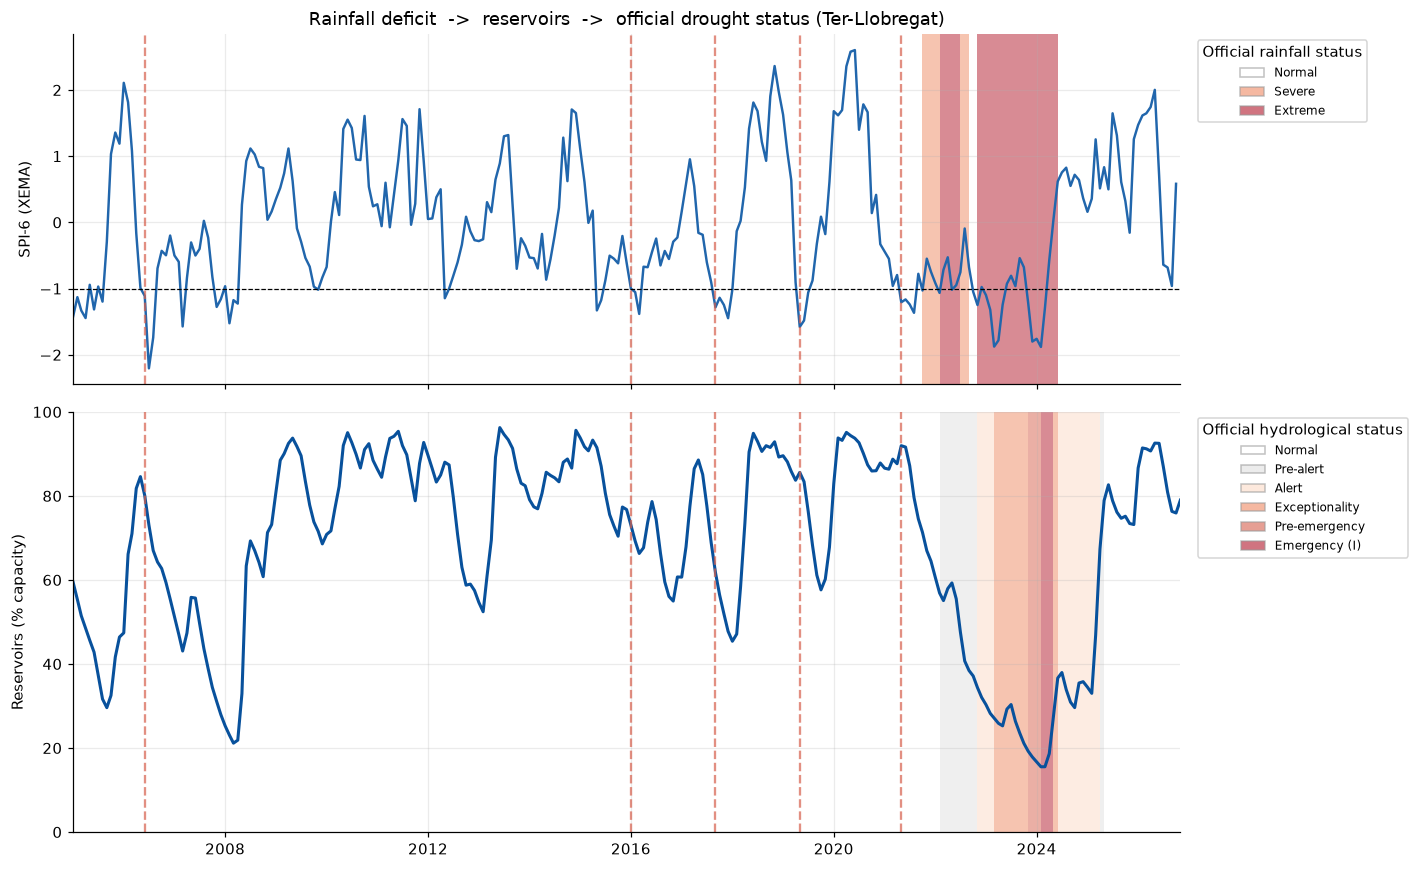

Map: 170 stations | mean anomaly -22% | driest -41% | wettest 5%


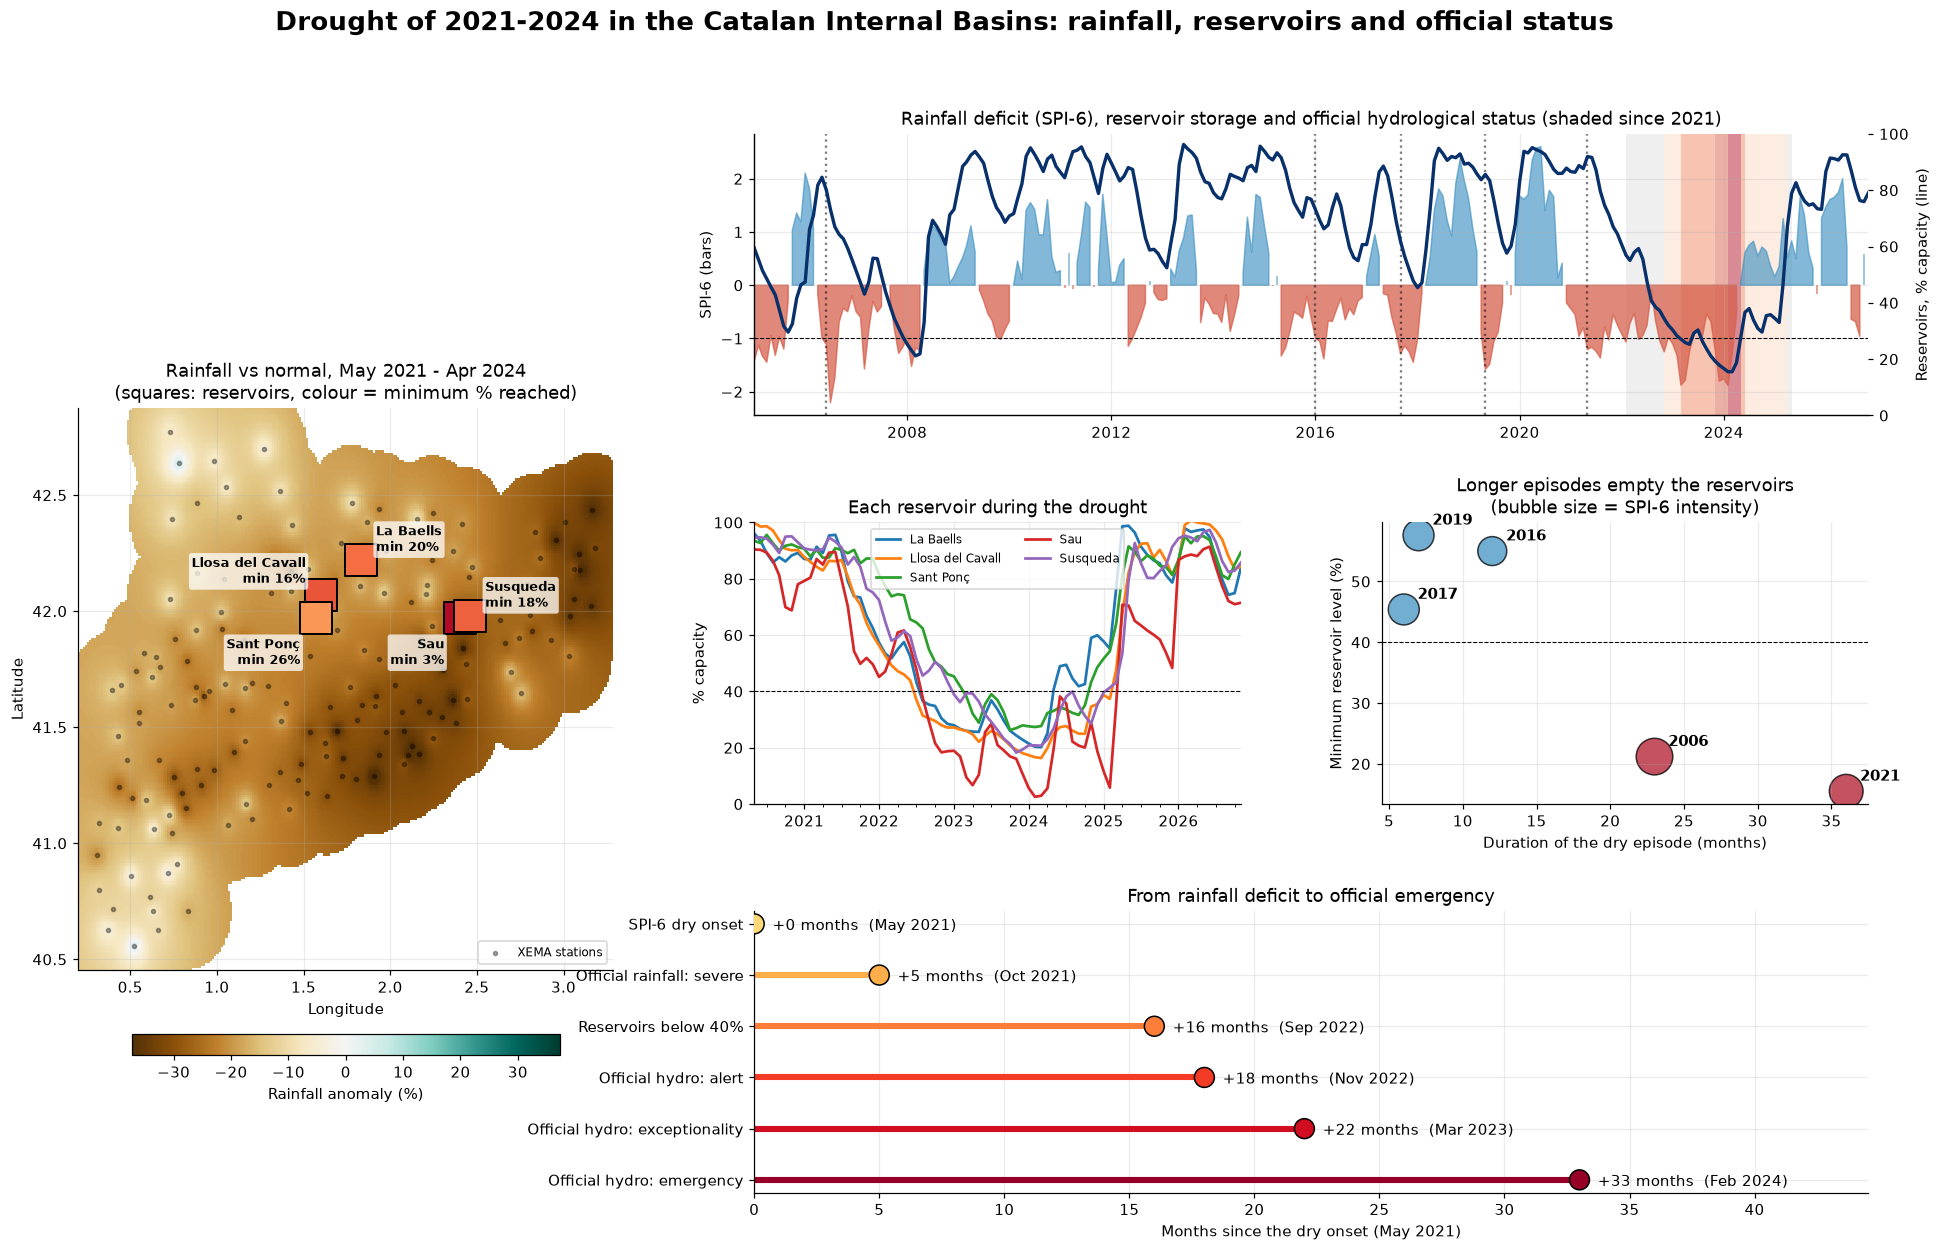

In [11]:
# %% [markdown]
# # Water block: dry episode -> reservoirs -> official drought status (Catalonia)
# **Question:** how many months pass between a rainfall deficit (XEMA) and its reflection in the reservoirs (ACA)
# and in the official drought status (ACA)?
# Output: one figure, one episode table, and a monthly CSV that other blocks (fires, heat) can reuse.

# %% 0. Setup
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

SOCRATA = "https://analisi.transparenciacatalunya.cat/resource/{}.csv?$limit=1000000"
load = lambda ds: pd.read_csv(SOCRATA.format(ds), low_memory=False).rename(columns=str.upper)

def pick(df, *names):
    for n in names:
        if n in df.columns:
            return n
    raise KeyError(f"None of {names} found. Columns: {list(df.columns)}")

def find(df, rx):
    """First column matching regex, ignoring code columns (we want names)."""
    cols = [c for c in df.columns if re.search(rx, c, re.I) and "CODI" not in c.upper()]
    if not cols:
        raise KeyError(f"No column matches '{rx}'. Columns: {list(df.columns)}")
    return cols[0]

def months_between(a, b):
    return (b.year - a.year) * 12 + b.month - a.month

UNIT_KEY = "terllobregat"    # matched ignoring spaces/hyphens (unit "Embassament Ter- Llobregat"); reference exploitation unit (Barcelona area; matches the reservoir system)
# Comarques draining to the Internal Basins (edit if your team defines the catchment differently)
CATCHMENT = ["Ripollès", "Osona", "Berguedà", "Bages", "Garrotxa", "Selva", "Gironès", "Anoia", "Moianès",
             "Vallès Occidental", "Vallès Oriental", "Maresme", "Baix Llobregat", "Alt Penedès", "Garraf",
             "Barcelonès", "Alt Empordà", "Baix Empordà", "Pla de l'Estany", "Solsonès"]

# %% 1. XEMA daily -> monthly regional SPI-6
path_xema = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"
PPT_NAME = "Precipitació acumulada diària"     # midnight-to-midnight daily total (not the 8-8h variant)

# The CSV has 33M rows: read in chunks and keep only daily precipitation (values use decimal commas -> read as text)
cols = ["CODI_ESTACIO", "DATA_LECTURA", "NOM_VARIABLE", "VALOR", "Estat"]
parts, n_rows = [], 0
for ch in pd.read_csv(path_xema, usecols=cols, dtype=str, chunksize=2_000_000):
    n_rows += len(ch)
    parts.append(ch[ch.NOM_VARIABLE == PPT_NAME])
ppt = pd.concat(parts)
print(f"Total rows: {n_rows:,} | daily precipitation rows: {len(ppt):,}")
print(ppt.Estat.value_counts(dropna=False))
if (ppt.Estat == "Representatiu").any():
    ppt = ppt[ppt.Estat == "Representatiu"]            # keep only data flagged as representative

daily = pd.DataFrame({"station": ppt.CODI_ESTACIO,
                      "date": pd.to_datetime(ppt.DATA_LECTURA, format="%d/%m/%Y", errors="coerce"),
                      "ppt": pd.to_numeric(ppt.VALOR.str.replace(",", ".", regex=False), errors="coerce")}).dropna(subset=["date"])
daily.loc[daily.ppt < 0, "ppt"] = np.nan
print(daily.date.min().date(), "->", daily.date.max().date(), "|", daily.station.nunique(), "stations")
stations = load("yqwd-vj5e")                            # station metadata (comarca)

# Monthly totals per station (partial months scaled to the full month; months with <25 days discarded)
daily["month"] = daily.date.dt.to_period("M").dt.to_timestamp()
mon = daily.groupby(["station", "month"]).ppt.agg(avg="mean", n="count").reset_index()
mon["ppt"] = (mon.avg * mon.month.dt.days_in_month).where(mon.n >= 25)
P = mon.pivot(index="month", columns="station", values="ppt").asfreq("MS")
P = P.loc[:, P.count() >= 120]                                   # stations with >= 10 years of data
P_all = P.copy()                                                 # all Catalonia (used by the map in cell 7)

s_id, s_com = pick(stations, "CODI_ESTACIO", "CODI"), next((c for c in ("NOM_COMARCA", "COMARCA") if c in stations.columns), None)
if s_com is None:
    print("WARNING: no comarca column in station metadata; using ALL stations. Columns:", list(stations.columns))
keep = set(stations[stations[s_com].isin(CATCHMENT)][s_id].astype(str)) if s_com else set(stations[s_id].astype(str))
P = P[[c for c in P.columns if str(c) in keep]]

# SPI-6: each station's 6-month accumulated rainfall as a ratio to its own normal for the same window
# (ratio of sums, not mean of monthly ratios), averaged over stations, then standardised over time.
acc6 = P.rolling(6, min_periods=6).sum()
ratio = acc6 / acc6.groupby(acc6.index.month).transform("mean")
reg = ratio.mean(axis=1).where(ratio.notna().sum(axis=1) >= 10)
spi6 = ((reg - reg.mean()) / reg.std()).rename("spi6")           # SPI-like index (no gamma fit)
print("Stations in catchment:", P.shape[1])

# %% 2. Reservoirs (ACA): system storage in % of capacity
res = load("gn9e-3qhr")
c_day, c_est = pick(res, "DIA", "DATA"), pick(res, "ESTACIO", "ESTACI", "EMBASSAMENT")
c_vol, c_pct = pick(res, "VOLUM_EMBASSAT"), pick(res, "PERCENTATGE_VOLUM_EMBASSAT")
res[c_day] = pd.to_datetime(res[c_day]).dt.normalize()
for c in (c_vol, c_pct):
    res[c] = pd.to_numeric(res[c], errors="coerce")
SYSTEM = r"\bsau\b|susqueda|baells|llosa del cavall|sant pon"   # reservoirs of the Ter-Llobregat unit
sel = res[c_est].astype(str).str.contains(SYSTEM, case=False, regex=True)
print("Included:", sorted(res[sel][c_est].unique()), "\nExcluded:", sorted(res[~sel][c_est].unique()))
if sel.any():
    res = res[sel]
else:
    print("WARNING: no reservoir matched SYSTEM, using all Internal Basins reservoirs")
res["cap"] = (res[c_vol] / (res[c_pct] / 100)).groupby(res[c_est]).transform("median")
sysd = res.groupby(c_day).agg(vol=(c_vol, "sum"), cap=("cap", "sum"), n=(c_est, "nunique"))
sysd = sysd[sysd.n >= 0.9 * sysd.n.max()]                       # drop days with missing reservoirs
resm = (100 * sysd.vol / sysd.cap).resample("MS").mean().rename("res")

# %% 3. Official drought status (ACA): change log -> monthly state of the reference unit
sq = load("i5n8-43cw")
print("Dimensions:", sq.shape); display(sq.head())
c_date, c_unit = find(sq, r"^data"), find(sq, r"unitat")
c_hyd, c_plu = find(sq, r"estat.*hidrol"), find(sq, r"estat.*pluvi")
print("Using ->", {"date": c_date, "unit": c_unit, "hydrological": c_hyd, "pluviometric": c_plu})
print("Hydrological values :", sq[c_hyd].dropna().unique()[:12])
print("Pluviometric values :", sq[c_plu].dropna().unique()[:12])

def lvl_hyd(x):
    """0 normal, 1 pre-alert, 2 alert, 3 exceptionality, 4 pre-emergency, 5/6/7 emergency I/II/III (plain 'emergència' = 5)."""
    x = str(x).lower()
    if "prealerta" in x: return 1
    if "preemerg" in x: return 4
    if "alerta" in x: return 2
    if "excepcional" in x: return 3
    if "emerg" in x:
        m = re.search(r"emerg\w*\s*(iii|ii|i)\b", x)
        return {"i": 5, "ii": 6, "iii": 7}[m.group(1) if m else "i"]
    return 0 if "normal" in x else np.nan

def lvl_plu(x):
    """0 normal, 1 moderate, 2 severe, 3 extreme."""
    x = str(x).lower()
    for k, v in (("extrem", 3), ("sever", 2), ("moderad", 1), ("normal", 0)):
        if k in x: return v
    return np.nan

sq["date"] = pd.to_datetime(sq[c_date], utc=True).dt.tz_localize(None)
ref = sq[sq[c_unit].astype(str).str.lower().str.replace(r"[\s\-]", "", regex=True).str.contains(UNIT_KEY)].sort_values("date")
if ref.empty:
    raise ValueError(f"No unit matches '{UNIT_KEY}'. Units: {sq[c_unit].unique()}")
ref = ref.assign(hyd=ref[c_hyd].map(lvl_hyd), plu=ref[c_plu].map(lvl_plu))
off = ref.set_index("date")[["hyd", "plu"]].resample("MS").last()
off = off.reindex(pd.date_range(off.index.min(), max(off.index.max(), resm.index.max()), freq="MS")).ffill()  # change log -> state in force each month
print("Official series:", f"{off.index.min():%Y-%m} -> {off.index.max():%Y-%m}")

# %% 4. Monthly table (shareable with the fires / heat blocks)
monthly = pd.concat([spi6, resm, off], axis=1).loc["2005-01":]
monthly.index.name = "month"
monthly.to_csv("water_monthly.csv")
display(monthly.dropna().tail())

# %% 5. Dry episodes and lags to each milestone
# Episode start = first month of >=3 consecutive months with SPI-6 <= -1 (runs already in progress when the series begins are
# discarded: censored). An episode ends when SPI-6 stays above 0 for 3 consecutive months; only then can a new one start
# (a single month slightly above 0 does not end a drought).
sp = monthly.spi6
dry, wet = sp <= -1, sp > 0
run3 = dry & dry.shift(-1, fill_value=False) & dry.shift(-2, fill_value=False)
wet3 = wet & wet.shift(-1, fill_value=False) & wet.shift(-2, fill_value=False)
starts = monthly.index[run3 & ~dry.shift(1, fill_value=True)]
onsets = []
for t in starts:
    if not onsets or wet3.loc[onsets[-1]:t].any():
        onsets.append(t)
ends = [min(o + pd.DateOffset(months=60), nxt) for o, nxt in zip(onsets, onsets[1:] + [pd.Timestamp.max])]

def lag(col, o, end, cond):
    """Months from onset until the series first meets cond, within the episode window; NaN if never / no data yet.
    0 means the condition already held at onset."""
    s = monthly[col].dropna()
    if s.empty or o < s.index.min():
        return np.nan
    w = s.loc[o:end]
    w = w[cond(w)]
    return months_between(o, w.index[0]) if len(w) else np.nan

rows = []
for o, e in zip(onsets, ends):
    w = monthly.res.loc[o:e]
    rows.append({"Dry onset": f"{o:%Y-%m}",
                 "Min SPI-6": round(monthly.spi6.loc[o:e].min(), 2),
                 "Duration [m]": next((months_between(o, t) for t in monthly.index[wet3] if t > o), np.nan),
                 "Reservoir % at onset": round(monthly.res.get(o, np.nan), 1),
                 "Min reservoir %": round(w.min(), 1) if w.notna().any() else np.nan,
                 "Reservoirs <40% [m]": lag("res", o, e, lambda s: s < 40),
                 "Official rain: severe [m]": lag("plu", o, e, lambda s: s >= 2),
                 "Official hydro: alert [m]": lag("hyd", o, e, lambda s: s >= 2),
                 "Official hydro: exceptionality [m]": lag("hyd", o, e, lambda s: s >= 3),
                 "Official hydro: emergency [m]": lag("hyd", o, e, lambda s: s >= 5)})
episodes = pd.DataFrame(rows)
display(episodes)

# %% 6. Figure: rainfall deficit -> reservoirs, each with its official status in the background
HYD = {0: ("Normal", "#ffffff"), 1: ("Pre-alert", "#e0e0e0"), 2: ("Alert", "#fddbc7"), 3: ("Exceptionality", "#ef8a62"),
       4: ("Pre-emergency", "#d6604d"), 5: ("Emergency (I)", "#b2182b"), 6: ("Emergency II", "#67001f"), 7: ("Emergency III", "#3d0010")}
PLU = {0: ("Normal", "#ffffff"), 1: ("Moderate", "#fddbc7"), 2: ("Severe", "#ef8a62"), 3: ("Extreme", "#b2182b")}

def shade(ax, s, pal, title=None):
    s = s.dropna()
    for _, g in s.groupby((s != s.shift()).cumsum()):
        ax.axvspan(g.index[0], g.index[-1] + pd.DateOffset(months=1), color=pal[int(g.iloc[0])][1], alpha=.5, lw=0)
    if title:
        ax.legend(handles=[Patch(facecolor=pal[i][1], edgecolor="#999", alpha=.6, label=pal[i][0]) for i in sorted(s.unique().astype(int))],
                  title=title, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
shade(ax[0], monthly.plu, PLU, "Official rainfall status")
ax[0].plot(monthly.index, monthly.spi6, color="#2166ac", lw=1.6)
ax[0].axhline(-1, ls="--", color="k", lw=.8); ax[0].set_ylabel("SPI-6 (XEMA)")
ax[0].set_title("Rainfall deficit  ->  reservoirs  ->  official drought status (Ter-Llobregat)")
shade(ax[1], monthly.hyd, HYD, "Official hydrological status")
ax[1].plot(monthly.index, monthly.res, color="#08519c", lw=2); ax[1].set_ylim(0, 100); ax[1].set_ylabel("Reservoirs (% capacity)")
for o in onsets:
    for a in ax:
        a.axvline(o, color="#d6604d", ls="--", alpha=.7)
ax[1].set_xlim(monthly.res.first_valid_index(), monthly.index.max())
plt.tight_layout(); plt.savefig("fig_water_chain.png", dpi=200, bbox_inches="tight"); plt.show()

# %% 7. Dashboard: where did it rain less, which reservoirs emptied, and the chain of lags (major drought)
from matplotlib.gridspec import GridSpec

# --- 7a. Episode to show: the one with the deepest reservoir minimum (override with ep = episodes.iloc[i])
ep = episodes.loc[episodes["Min reservoir %"].idxmin()]
o = pd.Timestamp(ep["Dry onset"] + "-01")
dur = int(ep["Duration [m]"]) if pd.notna(ep["Duration [m]"]) else months_between(o, monthly.index.max())
win = pd.date_range(o, periods=dur, freq="MS")

# --- 7b. Rainfall anomaly per station over the episode (% vs the station's own normal for the same months)
clim = P_all.groupby(P_all.index.month).mean()
Pw = P_all.reindex(win)
Cw = clim.reindex(win.month).set_axis(win).where(Pw.notna())
anom = ((Pw.sum() / Cw.sum() - 1) * 100)[Pw.notna().mean() >= .8].rename(index=str).rename("a")

lat_c, lon_c = pick(stations, "LATITUD", "LAT", "LATITUDE"), pick(stations, "LONGITUD", "LON", "LONGITUDE")
coords = (stations.drop_duplicates(s_id).assign(k=lambda x: x[s_id].astype(str)).set_index("k")[[lon_c, lat_c]]
          .apply(pd.to_numeric, errors="coerce"))
pts = coords.join(anom, how="inner").dropna()
print(f"Map: {len(pts)} stations | mean anomaly {pts.a.mean():.0f}% | driest {pts.a.min():.0f}% | wettest {pts.a.max():.0f}%")

# --- 7c. Smooth surface (inverse-distance weighting), clipped to Catalonia if the boundary can be downloaded
def catalonia_outline():
    try:
        import geopandas as gpd
        g = gpd.read_file("https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_1_states_provinces.zip")
        g = g[g["iso_3166_2"].isin(["ES-B", "ES-GI", "ES-L", "ES-T"])]
        return g.geometry.unary_union if len(g) else None
    except Exception as e:
        print("Boundary not available (", type(e).__name__, ") -> using the station footprint instead")
        return None
outline = catalonia_outline()

X = np.linspace(pts[lon_c].min() - .1, pts[lon_c].max() + .1, 240)
Y = np.linspace(pts[lat_c].min() - .1, pts[lat_c].max() + .1, 240)
gx, gy = np.meshgrid(X, Y)
d2 = (gx[..., None] - pts[lon_c].values) ** 2 + (gy[..., None] - pts[lat_c].values) ** 2
w = 1 / (d2 + 1e-6)
Z = (w * pts.a.values).sum(-1) / w.sum(-1)
if outline is not None:
    import shapely
    Z[~shapely.contains_xy(outline, gx, gy)] = np.nan
else:
    Z[np.sqrt(d2.min(-1)) > .25] = np.nan

# --- 7d. Reservoirs: approximate dam coordinates (for display only) + per-reservoir series
RES_XY = {r"\bsau\b": ("Sau", 2.40, 41.97, -10, -30, "right"), r"susqueda": ("Susqueda", 2.46, 41.98, 10, 6, "left"),
          r"baells": ("La Baells", 1.83, 42.22, 10, 6, "left"), r"llosa": ("Llosa del Cavall", 1.60, 42.07, -10, 8, "right"),
          r"sant pon": ("Sant Ponç", 1.57, 41.97, -10, -30, "right")}
def short(n):
    return next((v[0] for rx, v in RES_XY.items() if re.search(rx, str(n), re.I)), str(n))
resd = res.assign(month=res[c_day].dt.to_period("M").dt.to_timestamp(), est=res[c_est].map(short))
resp = resd.groupby(["month", "est"])[c_pct].mean().unstack()
rmin = resp.loc[o:o + pd.DateOffset(months=dur + 12)].min()

# --- 7e. Figure
fig = plt.figure(figsize=(21, 12.5))
gs = GridSpec(3, 3, figure=fig, width_ratios=[1.1, 1, 1], hspace=.38, wspace=.28)
axm, axt = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1:])
axr, axs, axd = fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[1, 2]), fig.add_subplot(gs[2, 1:])

# Map
v = max(np.nanpercentile(np.abs(pts.a), 95), 10)
mesh = axm.pcolormesh(gx, gy, Z, cmap="BrBG", vmin=-v, vmax=v, shading="auto")
if outline is not None:
    import geopandas as gpd
    gpd.GeoSeries([outline]).boundary.plot(ax=axm, color="#333", lw=.9)
axm.scatter(pts[lon_c], pts[lat_c], s=7, c="k", alpha=.35, label="XEMA stations")
for rx, (lab, lon, lat, dx, dy, ha) in RES_XY.items():
    m = rmin.get(lab, np.nan)
    axm.scatter(lon, lat, s=420, c=[m], cmap="RdYlBu", vmin=0, vmax=100, edgecolor="k", linewidth=1.3, marker="s", zorder=5)
    axm.annotate(f"{lab}\nmin {m:.0f}%", (lon, lat), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=8.5, weight="bold", zorder=6,
                  bbox=dict(boxstyle="round,pad=.2", fc="white", alpha=.75, lw=0))
axm.set_aspect(1 / np.cos(np.radians(41.7))); axm.set_anchor("C")
axm.set_title(f"Rainfall vs normal, {win[0]:%b %Y} - {win[-1]:%b %Y}\n(squares: reservoirs, colour = minimum % reached)", fontsize=12)
cb = plt.colorbar(mesh, ax=axm, orientation="horizontal", pad=.06, shrink=.8); cb.set_label("Rainfall anomaly (%)")
axm.legend(loc="lower right", fontsize=8); axm.set_xlabel("Longitude"); axm.set_ylabel("Latitude")

# Timeline: SPI-6 + reservoirs + official hydrological status
shade(axt, monthly.hyd, HYD)
axt.fill_between(monthly.index, monthly.spi6, 0, where=monthly.spi6 >= 0, color="#4393c3", alpha=.65)
axt.fill_between(monthly.index, monthly.spi6, 0, where=monthly.spi6 < 0, color="#d6604d", alpha=.75)
axt.axhline(-1, ls="--", color="k", lw=.7); axt.set_ylabel("SPI-6 (bars)")
ax2 = axt.twinx(); ax2.plot(monthly.index, monthly.res, color="#08306b", lw=2.2); ax2.set_ylim(0, 100)
ax2.set_ylabel("Reservoirs, % capacity (line)"); ax2.grid(False)
for t in onsets:
    axt.axvline(t, color="k", ls=":", alpha=.5)
axt.set_xlim(monthly.index.min(), monthly.index.max())
axt.set_title("Rainfall deficit (SPI-6), reservoir storage and official hydrological status (shaded since 2021)", fontsize=12)

# Per-reservoir curves
resp.loc[o - pd.DateOffset(months=12):].plot(ax=axr, lw=1.8, legend=True)
axr.axhline(40, ls="--", color="k", lw=.7); axr.set_ylim(0, 100); axr.set_xlabel("")
axr.set_ylabel("% capacity"); axr.set_title("Each reservoir during the drought", fontsize=12); axr.legend(fontsize=8, ncol=2)

# Duration vs depth of the reservoir minimum
e = episodes
axs.scatter(e["Duration [m]"], e["Min reservoir %"], s=(-e["Min SPI-6"]) * 260, c=np.where(e["Min reservoir %"] < 40, "#b2182b", "#4393c3"),
            alpha=.75, edgecolor="k")
for _, r in e.iterrows():
    axs.annotate(r["Dry onset"][:4], (r["Duration [m]"], r["Min reservoir %"]), xytext=(9, 7), textcoords="offset points", weight="bold")
axs.axhline(40, ls="--", color="k", lw=.7)
axs.set_xlabel("Duration of the dry episode (months)"); axs.set_ylabel("Minimum reservoir level (%)")
axs.set_title("Longer episodes empty the reservoirs\n(bubble size = SPI-6 intensity)", fontsize=12)

# Chain of lags
ms = [("SPI-6 dry onset", 0), ("Official rainfall: severe", ep["Official rain: severe [m]"]),
      ("Reservoirs below 40%", ep["Reservoirs <40% [m]"]), ("Official hydro: alert", ep["Official hydro: alert [m]"]),
      ("Official hydro: exceptionality", ep["Official hydro: exceptionality [m]"]), ("Official hydro: emergency", ep["Official hydro: emergency [m]"])]
ms = sorted([(n, x) for n, x in ms if pd.notna(x)], key=lambda t: t[1])
yy = np.arange(len(ms))[::-1]
cols = plt.cm.YlOrRd(np.linspace(.25, .95, len(ms)))
axd.hlines(yy, 0, [x for _, x in ms], color=cols, lw=4); axd.scatter([x for _, x in ms], yy, s=170, c=cols, edgecolor="k", zorder=3)
for (n, x), y_ in zip(ms, yy):
    axd.annotate(f"+{x:.0f} months  ({o + pd.DateOffset(months=int(x)):%b %Y})", (x, y_), xytext=(12, -4), textcoords="offset points", fontsize=10)
axd.set_yticks(yy, [n for n, _ in ms]); axd.set_xlim(0, max(x for _, x in ms) * 1.35)
axd.set_xlabel(f"Months since the dry onset ({o:%b %Y})"); axd.set_title("From rainfall deficit to official emergency", fontsize=12)

fig.suptitle(f"Drought of {o:%Y}-{win[-1]:%Y} in the Catalan Internal Basins: rainfall, reservoirs and official status", fontsize=17, weight="bold", y=.97)
plt.savefig("fig_water_dashboard.png", dpi=220, bbox_inches="tight"); plt.show()

Total rows: 33,475,032 | daily precipitation rows: 1,850,932
Estat
Representatiu       1850918
No representatiu         14
Name: count, dtype: int64
1988-09-01 -> 2026-11-14 | 243 stations
Stations in catchment: 96
Included: ['Embassament de Sant Ponç (Clariana de Cardener)', 'Embassament de Sau (Vilanova de Sau)', 'Embassament de Susqueda (Osor)', 'Embassament de la Baells (Cercs)', 'Embassament de la Llosa del Cavall (Navès)'] 
Excluded: ['Embassament de Darnius Boadella (Darnius)', 'Embassament de Foix (Castellet i la Gornal)', 'Embassament de Riudecanyes', 'Embassament de Siurana (Cornudella de Montsant)']
Dimensions: (8677, 9)


,DATA_CANVI_ESTAT_SEQUERA,CODI_UNITAT_EXPLOTACI,UNITAT_EXPLOTACI,CODI_ESTAT_SEQUERA_HIDROL,ESTAT_SEQUERA_HIDROL_GIC,CODI_ESTAT_SEQUERA_PLUVIOM,ESTAT_SEQUERA_PLUVIOM_TRIC,CODI_MUNICIPI,MUNICIPI
0,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170010,Agullana
1,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170118,"Armentera, l'"
2,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170427,Capmany
3,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170643,Espolla
4,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170773,Garriguella


Using -> {'date': 'DATA_CANVI_ESTAT_SEQUERA', 'unit': 'UNITAT_EXPLOTACI', 'hydrological': 'ESTAT_SEQUERA_HIDROL_GIC', 'pluviometric': 'ESTAT_SEQUERA_PLUVIOM_TRIC'}
Hydrological values : <ArrowStringArray>
[     'NORMALITAT',          'ALERTA',       'PREALERTA', 'EXCEPCIONALITAT',
      'EMERGÈNCIA',    'EMERGÈNCIA I',   'EMERGÈNCIA II',   'PREEMERGÈNCIA']
Length: 8, dtype: str
Pluviometric values : <ArrowStringArray>
['NORMALITAT', 'SEQUERA SEVERA', 'SEQUERA EXTREMA']
Length: 3, dtype: str
Official series: 2021-01 -> 2026-11


,spi6,res,hyd,plu
month,,,,
2026-06-01,0.710891,92.523616,0.0,0.0
2026-07-01,-0.639575,87.036281,0.0,0.0
2026-08-01,-0.681915,80.902853,0.0,0.0
2026-09-01,-0.961469,76.325014,0.0,0.0
2026-10-01,0.582508,75.943038,0.0,0.0


,Dry onset,Min SPI-6,Duration [m],Reservoir % at onset,Min reservoir %,Reservoirs <40% [m],Official rain: severe [m],Official hydro: alert [m],Official hydro: exceptionality [m],Official hydro: emergency [m]
0,2006-06,-2.21,23,80.1,21.2,15.0,NaN,NaN,NaN,NaN
1,2016-01,-1.38,12,73.1,55.0,NaN,NaN,NaN,NaN,NaN
2,2017-09,-1.58,6,61.8,45.4,NaN,NaN,NaN,NaN,NaN
3,2019-05,-1.58,7,85.6,57.6,NaN,NaN,NaN,NaN,NaN
4,2021-05,-1.88,36,92.0,15.5,16.0,5.0,18.0,22.0,33.0


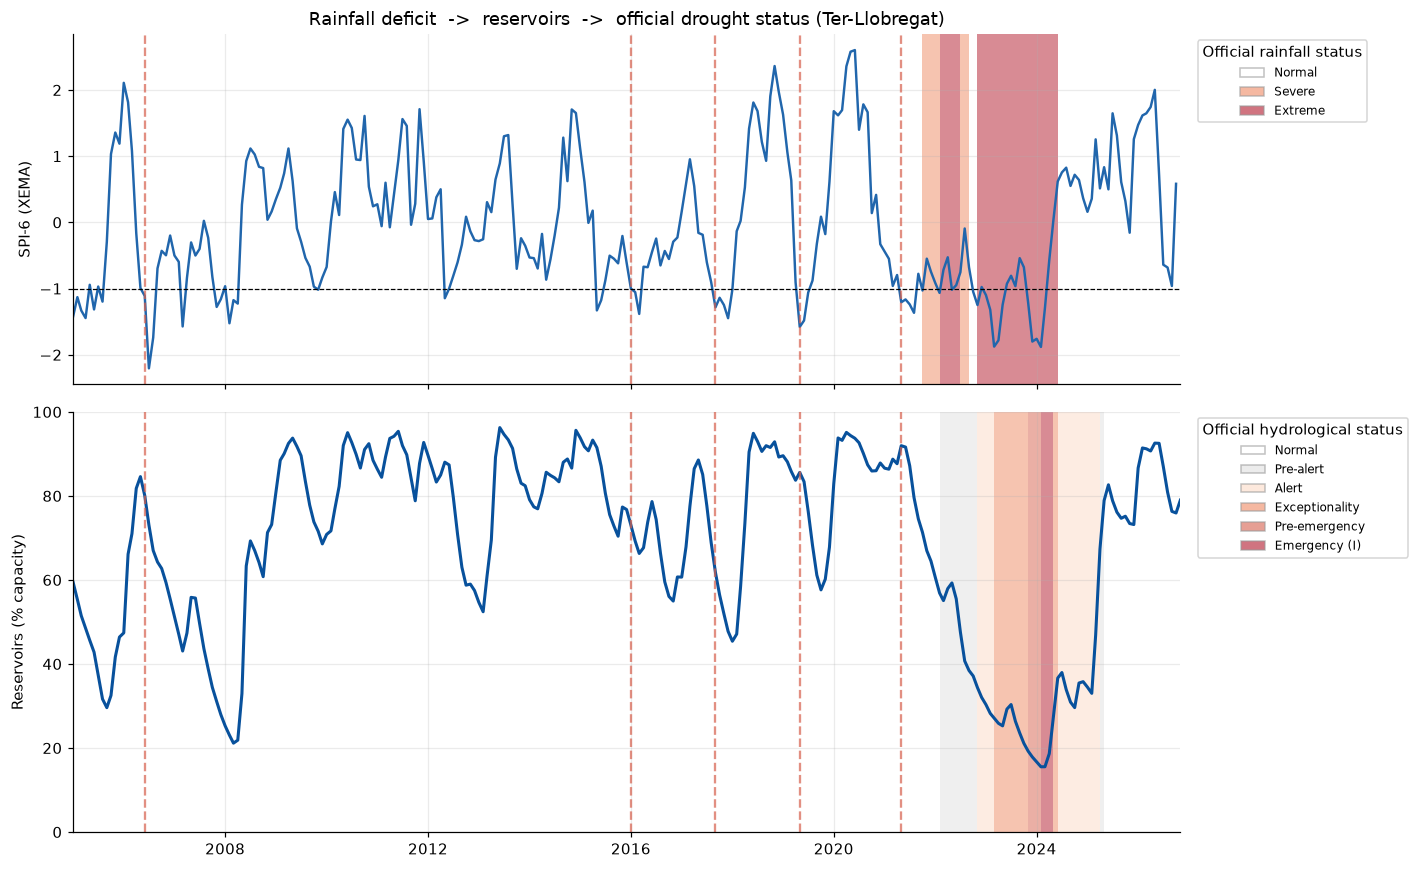

Map: 170 stations | mean anomaly -22% | driest -41% | wettest 5%


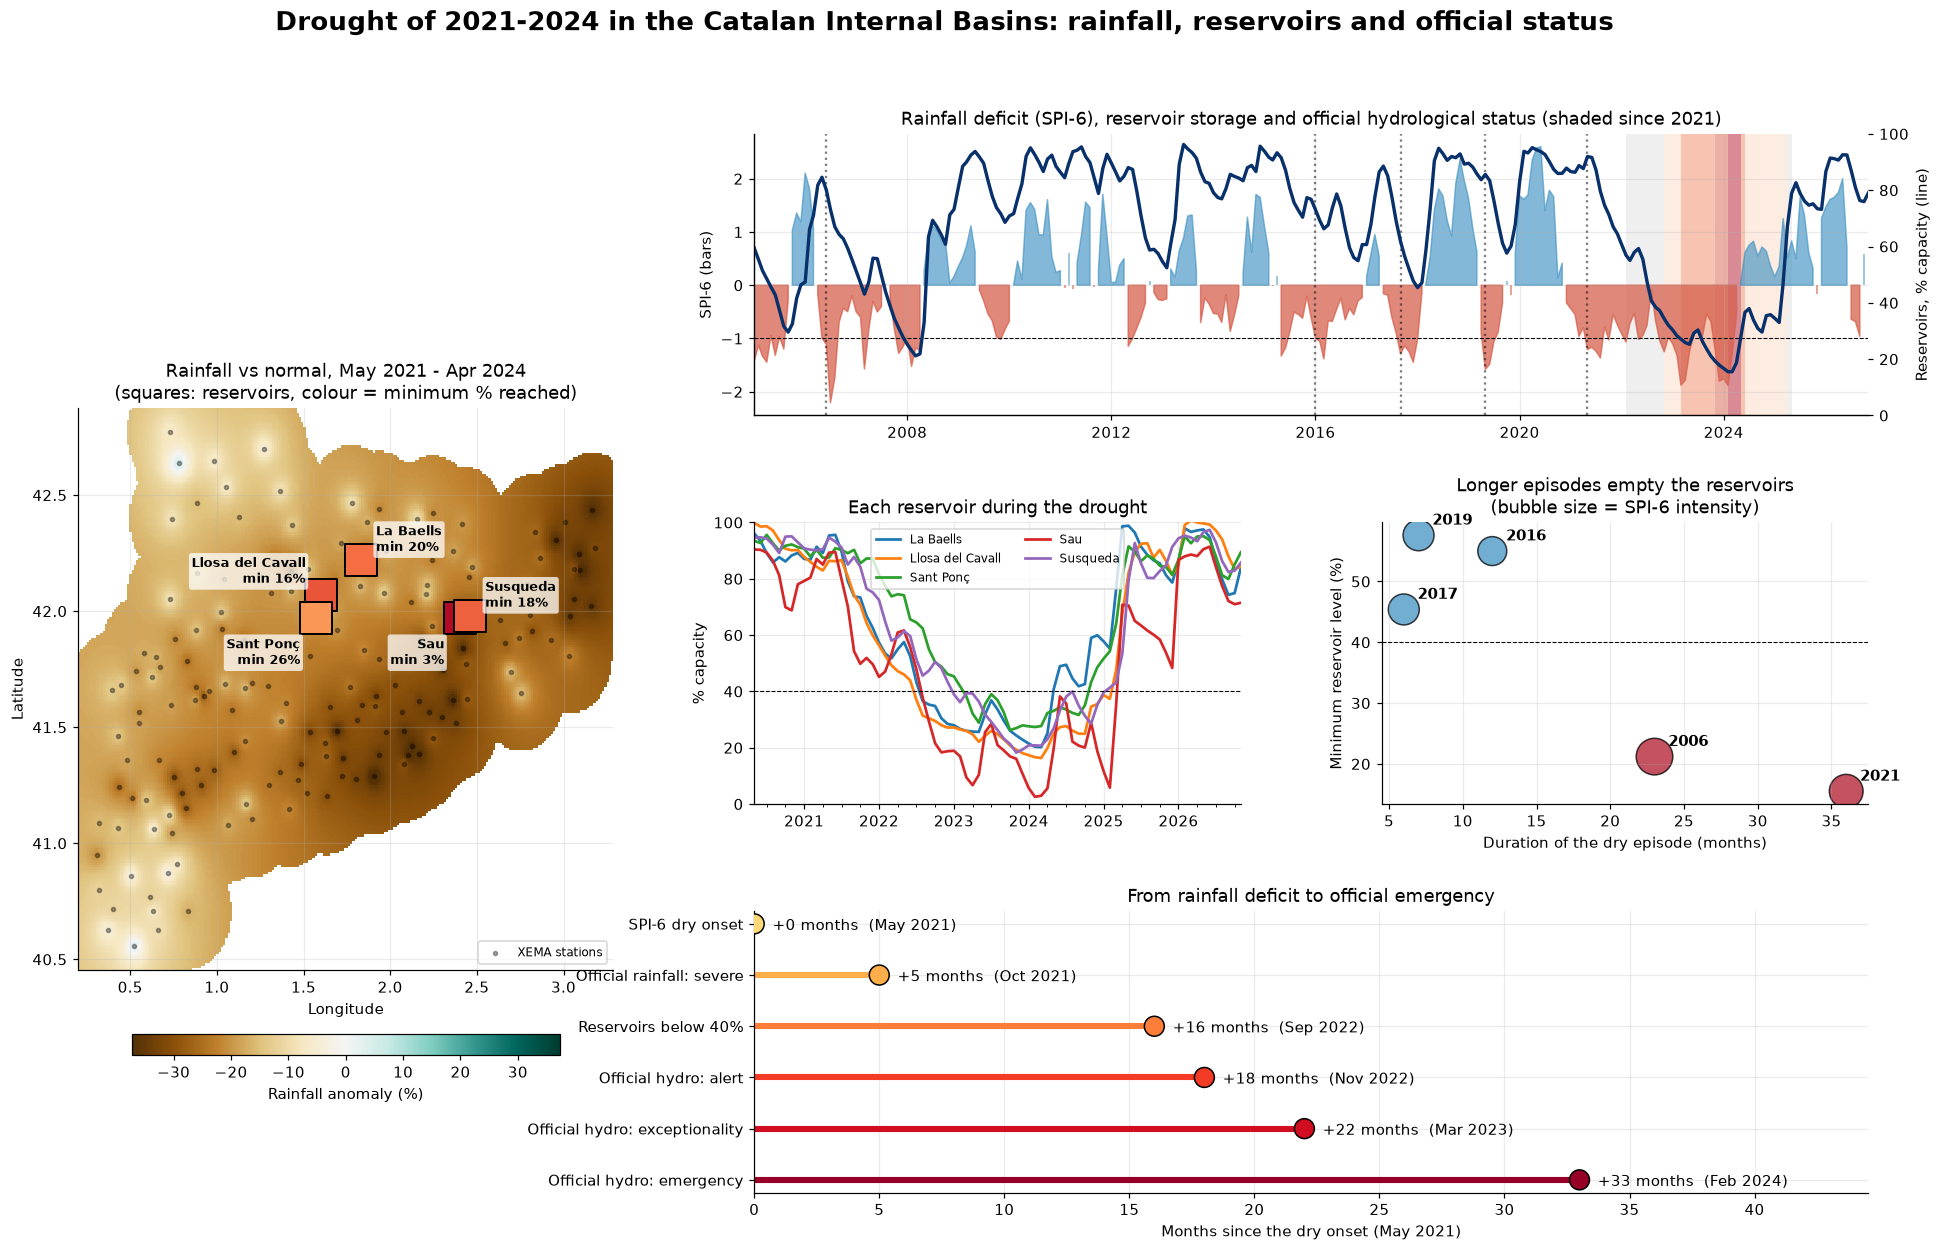

630 municipalities | 18 units | 2021-01 -> 2026-11
Municipalities belonging to more than one unit: 4


,municipi_code,municipi,unit,month,hyd,plu
45009,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-07-01,0.0,0.0
45010,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-08-01,0.0,0.0
45011,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-09-01,0.0,0.0
45012,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-10-01,0.0,0.0
45013,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-11-01,0.0,0.0


In [12]:
# este es como para municipios tmb

# # Water block: dry episode -> reservoirs -> official drought status (Catalonia)
# **Question:** how many months pass between a rainfall deficit (XEMA) and its reflection in the reservoirs (ACA)
# and in the official drought status (ACA)?
# Output: one figure, one episode table, and a monthly CSV that other blocks (fires, heat) can reuse.

# %% 0. Setup
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

SOCRATA = "https://analisi.transparenciacatalunya.cat/resource/{}.csv?$limit=1000000"
load = lambda ds: pd.read_csv(SOCRATA.format(ds), low_memory=False).rename(columns=str.upper)

def pick(df, *names):
    for n in names:
        if n in df.columns:
            return n
    raise KeyError(f"None of {names} found. Columns: {list(df.columns)}")

def find(df, rx):
    """First column matching regex, ignoring code columns (we want names)."""
    cols = [c for c in df.columns if re.search(rx, c, re.I) and "CODI" not in c.upper()]
    if not cols:
        raise KeyError(f"No column matches '{rx}'. Columns: {list(df.columns)}")
    return cols[0]

def months_between(a, b):
    return (b.year - a.year) * 12 + b.month - a.month

UNIT_KEY = "terllobregat"    # matched ignoring spaces/hyphens (unit "Embassament Ter- Llobregat"); reference exploitation unit (Barcelona area; matches the reservoir system)
# Comarques draining to the Internal Basins (edit if your team defines the catchment differently)
CATCHMENT = ["Ripollès", "Osona", "Berguedà", "Bages", "Garrotxa", "Selva", "Gironès", "Anoia", "Moianès",
             "Vallès Occidental", "Vallès Oriental", "Maresme", "Baix Llobregat", "Alt Penedès", "Garraf",
             "Barcelonès", "Alt Empordà", "Baix Empordà", "Pla de l'Estany", "Solsonès"]

# %% 1. XEMA daily -> monthly regional SPI-6
path_xema = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"
PPT_NAME = "Precipitació acumulada diària"     # midnight-to-midnight daily total (not the 8-8h variant)

# The CSV has 33M rows: read in chunks and keep only daily precipitation (values use decimal commas -> read as text)
cols = ["CODI_ESTACIO", "DATA_LECTURA", "NOM_VARIABLE", "VALOR", "Estat"]
parts, n_rows = [], 0
for ch in pd.read_csv(path_xema, usecols=cols, dtype=str, chunksize=2_000_000):
    n_rows += len(ch)
    parts.append(ch[ch.NOM_VARIABLE == PPT_NAME])
ppt = pd.concat(parts)
print(f"Total rows: {n_rows:,} | daily precipitation rows: {len(ppt):,}")
print(ppt.Estat.value_counts(dropna=False))
if (ppt.Estat == "Representatiu").any():
    ppt = ppt[ppt.Estat == "Representatiu"]            # keep only data flagged as representative

daily = pd.DataFrame({"station": ppt.CODI_ESTACIO,
                      "date": pd.to_datetime(ppt.DATA_LECTURA, format="%d/%m/%Y", errors="coerce"),
                      "ppt": pd.to_numeric(ppt.VALOR.str.replace(",", ".", regex=False), errors="coerce")}).dropna(subset=["date"])
daily.loc[daily.ppt < 0, "ppt"] = np.nan
print(daily.date.min().date(), "->", daily.date.max().date(), "|", daily.station.nunique(), "stations")
stations = load("yqwd-vj5e")                            # station metadata (comarca)

# Monthly totals per station (partial months scaled to the full month; months with <25 days discarded)
daily["month"] = daily.date.dt.to_period("M").dt.to_timestamp()
mon = daily.groupby(["station", "month"]).ppt.agg(avg="mean", n="count").reset_index()
mon["ppt"] = (mon.avg * mon.month.dt.days_in_month).where(mon.n >= 25)
P = mon.pivot(index="month", columns="station", values="ppt").asfreq("MS")
P = P.loc[:, P.count() >= 120]                                   # stations with >= 10 years of data
P_all = P.copy()                                                 # all Catalonia (used by the map in cell 7)

s_id, s_com = pick(stations, "CODI_ESTACIO", "CODI"), next((c for c in ("NOM_COMARCA", "COMARCA") if c in stations.columns), None)
if s_com is None:
    print("WARNING: no comarca column in station metadata; using ALL stations. Columns:", list(stations.columns))
keep = set(stations[stations[s_com].isin(CATCHMENT)][s_id].astype(str)) if s_com else set(stations[s_id].astype(str))
P = P[[c for c in P.columns if str(c) in keep]]

# SPI-6: each station's 6-month accumulated rainfall as a ratio to its own normal for the same window
# (ratio of sums, not mean of monthly ratios), averaged over stations, then standardised over time.
acc6 = P.rolling(6, min_periods=6).sum()
ratio = acc6 / acc6.groupby(acc6.index.month).transform("mean")
reg = ratio.mean(axis=1).where(ratio.notna().sum(axis=1) >= 10)
spi6 = ((reg - reg.mean()) / reg.std()).rename("spi6")           # SPI-like index (no gamma fit)
print("Stations in catchment:", P.shape[1])

# %% 2. Reservoirs (ACA): system storage in % of capacity
res = load("gn9e-3qhr")
c_day, c_est = pick(res, "DIA", "DATA"), pick(res, "ESTACIO", "ESTACI", "EMBASSAMENT")
c_vol, c_pct = pick(res, "VOLUM_EMBASSAT"), pick(res, "PERCENTATGE_VOLUM_EMBASSAT")
res[c_day] = pd.to_datetime(res[c_day]).dt.normalize()
for c in (c_vol, c_pct):
    res[c] = pd.to_numeric(res[c], errors="coerce")
SYSTEM = r"\bsau\b|susqueda|baells|llosa del cavall|sant pon"   # reservoirs of the Ter-Llobregat unit
sel = res[c_est].astype(str).str.contains(SYSTEM, case=False, regex=True)
print("Included:", sorted(res[sel][c_est].unique()), "\nExcluded:", sorted(res[~sel][c_est].unique()))
if sel.any():
    res = res[sel]
else:
    print("WARNING: no reservoir matched SYSTEM, using all Internal Basins reservoirs")
res["cap"] = (res[c_vol] / (res[c_pct] / 100)).groupby(res[c_est]).transform("median")
sysd = res.groupby(c_day).agg(vol=(c_vol, "sum"), cap=("cap", "sum"), n=(c_est, "nunique"))
sysd = sysd[sysd.n >= 0.9 * sysd.n.max()]                       # drop days with missing reservoirs
resm = (100 * sysd.vol / sysd.cap).resample("MS").mean().rename("res")

# %% 3. Official drought status (ACA): change log -> monthly state of the reference unit
sq = load("i5n8-43cw")
print("Dimensions:", sq.shape); display(sq.head())
c_date, c_unit = find(sq, r"^data"), find(sq, r"unitat")
c_hyd, c_plu = find(sq, r"estat.*hidrol"), find(sq, r"estat.*pluvi")
print("Using ->", {"date": c_date, "unit": c_unit, "hydrological": c_hyd, "pluviometric": c_plu})
print("Hydrological values :", sq[c_hyd].dropna().unique()[:12])
print("Pluviometric values :", sq[c_plu].dropna().unique()[:12])

def lvl_hyd(x):
    """0 normal, 1 pre-alert, 2 alert, 3 exceptionality, 4 pre-emergency, 5/6/7 emergency I/II/III (plain 'emergència' = 5)."""
    x = str(x).lower()
    if "prealerta" in x: return 1
    if "preemerg" in x: return 4
    if "alerta" in x: return 2
    if "excepcional" in x: return 3
    if "emerg" in x:
        m = re.search(r"emerg\w*\s*(iii|ii|i)\b", x)
        return {"i": 5, "ii": 6, "iii": 7}[m.group(1) if m else "i"]
    return 0 if "normal" in x else np.nan

def lvl_plu(x):
    """0 normal, 1 moderate, 2 severe, 3 extreme."""
    x = str(x).lower()
    for k, v in (("extrem", 3), ("sever", 2), ("moderad", 1), ("normal", 0)):
        if k in x: return v
    return np.nan

sq["date"] = pd.to_datetime(sq[c_date], utc=True).dt.tz_localize(None)
ref = sq[sq[c_unit].astype(str).str.lower().str.replace(r"[\s\-]", "", regex=True).str.contains(UNIT_KEY)].sort_values("date")
if ref.empty:
    raise ValueError(f"No unit matches '{UNIT_KEY}'. Units: {sq[c_unit].unique()}")
ref = ref.assign(hyd=ref[c_hyd].map(lvl_hyd), plu=ref[c_plu].map(lvl_plu))
off = ref.set_index("date")[["hyd", "plu"]].resample("MS").last()
off = off.reindex(pd.date_range(off.index.min(), max(off.index.max(), resm.index.max()), freq="MS")).ffill()  # change log -> state in force each month
print("Official series:", f"{off.index.min():%Y-%m} -> {off.index.max():%Y-%m}")

# %% 4. Monthly table (shareable with the fires / heat blocks)
monthly = pd.concat([spi6, resm, off], axis=1).loc["2005-01":]
monthly.index.name = "month"
monthly.to_csv("water_monthly.csv")
display(monthly.dropna().tail())

# %% 5. Dry episodes and lags to each milestone
# Episode start = first month of >=3 consecutive months with SPI-6 <= -1 (runs already in progress when the series begins are
# discarded: censored). An episode ends when SPI-6 stays above 0 for 3 consecutive months; only then can a new one start
# (a single month slightly above 0 does not end a drought).
sp = monthly.spi6
dry, wet = sp <= -1, sp > 0
run3 = dry & dry.shift(-1, fill_value=False) & dry.shift(-2, fill_value=False)
wet3 = wet & wet.shift(-1, fill_value=False) & wet.shift(-2, fill_value=False)
starts = monthly.index[run3 & ~dry.shift(1, fill_value=True)]
onsets = []
for t in starts:
    if not onsets or wet3.loc[onsets[-1]:t].any():
        onsets.append(t)
ends = [min(o + pd.DateOffset(months=60), nxt) for o, nxt in zip(onsets, onsets[1:] + [pd.Timestamp.max])]

def lag(col, o, end, cond):
    """Months from onset until the series first meets cond, within the episode window; NaN if never / no data yet.
    0 means the condition already held at onset."""
    s = monthly[col].dropna()
    if s.empty or o < s.index.min():
        return np.nan
    w = s.loc[o:end]
    w = w[cond(w)]
    return months_between(o, w.index[0]) if len(w) else np.nan

rows = []
for o, e in zip(onsets, ends):
    w = monthly.res.loc[o:e]
    rows.append({"Dry onset": f"{o:%Y-%m}",
                 "Min SPI-6": round(monthly.spi6.loc[o:e].min(), 2),
                 "Duration [m]": next((months_between(o, t) for t in monthly.index[wet3] if t > o), np.nan),
                 "Reservoir % at onset": round(monthly.res.get(o, np.nan), 1),
                 "Min reservoir %": round(w.min(), 1) if w.notna().any() else np.nan,
                 "Reservoirs <40% [m]": lag("res", o, e, lambda s: s < 40),
                 "Official rain: severe [m]": lag("plu", o, e, lambda s: s >= 2),
                 "Official hydro: alert [m]": lag("hyd", o, e, lambda s: s >= 2),
                 "Official hydro: exceptionality [m]": lag("hyd", o, e, lambda s: s >= 3),
                 "Official hydro: emergency [m]": lag("hyd", o, e, lambda s: s >= 5)})
episodes = pd.DataFrame(rows)
display(episodes)

# %% 6. Figure: rainfall deficit -> reservoirs, each with its official status in the background
HYD = {0: ("Normal", "#ffffff"), 1: ("Pre-alert", "#e0e0e0"), 2: ("Alert", "#fddbc7"), 3: ("Exceptionality", "#ef8a62"),
       4: ("Pre-emergency", "#d6604d"), 5: ("Emergency (I)", "#b2182b"), 6: ("Emergency II", "#67001f"), 7: ("Emergency III", "#3d0010")}
PLU = {0: ("Normal", "#ffffff"), 1: ("Moderate", "#fddbc7"), 2: ("Severe", "#ef8a62"), 3: ("Extreme", "#b2182b")}

def shade(ax, s, pal, title=None):
    s = s.dropna()
    for _, g in s.groupby((s != s.shift()).cumsum()):
        ax.axvspan(g.index[0], g.index[-1] + pd.DateOffset(months=1), color=pal[int(g.iloc[0])][1], alpha=.5, lw=0)
    if title:
        ax.legend(handles=[Patch(facecolor=pal[i][1], edgecolor="#999", alpha=.6, label=pal[i][0]) for i in sorted(s.unique().astype(int))],
                  title=title, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
shade(ax[0], monthly.plu, PLU, "Official rainfall status")
ax[0].plot(monthly.index, monthly.spi6, color="#2166ac", lw=1.6)
ax[0].axhline(-1, ls="--", color="k", lw=.8); ax[0].set_ylabel("SPI-6 (XEMA)")
ax[0].set_title("Rainfall deficit  ->  reservoirs  ->  official drought status (Ter-Llobregat)")
shade(ax[1], monthly.hyd, HYD, "Official hydrological status")
ax[1].plot(monthly.index, monthly.res, color="#08519c", lw=2); ax[1].set_ylim(0, 100); ax[1].set_ylabel("Reservoirs (% capacity)")
for o in onsets:
    for a in ax:
        a.axvline(o, color="#d6604d", ls="--", alpha=.7)
ax[1].set_xlim(monthly.res.first_valid_index(), monthly.index.max())
plt.tight_layout(); plt.savefig("fig_water_chain.png", dpi=200, bbox_inches="tight"); plt.show()

# %% 7. Dashboard: where did it rain less, which reservoirs emptied, and the chain of lags (major drought)
from matplotlib.gridspec import GridSpec

# --- 7a. Episode to show: the one with the deepest reservoir minimum (override with ep = episodes.iloc[i])
ep = episodes.loc[episodes["Min reservoir %"].idxmin()]
o = pd.Timestamp(ep["Dry onset"] + "-01")
dur = int(ep["Duration [m]"]) if pd.notna(ep["Duration [m]"]) else months_between(o, monthly.index.max())
win = pd.date_range(o, periods=dur, freq="MS")

# --- 7b. Rainfall anomaly per station over the episode (% vs the station's own normal for the same months)
clim = P_all.groupby(P_all.index.month).mean()
Pw = P_all.reindex(win)
Cw = clim.reindex(win.month).set_axis(win).where(Pw.notna())
anom = ((Pw.sum() / Cw.sum() - 1) * 100)[Pw.notna().mean() >= .8].rename(index=str).rename("a")

lat_c, lon_c = pick(stations, "LATITUD", "LAT", "LATITUDE"), pick(stations, "LONGITUD", "LON", "LONGITUDE")
coords = (stations.drop_duplicates(s_id).assign(k=lambda x: x[s_id].astype(str)).set_index("k")[[lon_c, lat_c]]
          .apply(pd.to_numeric, errors="coerce"))
pts = coords.join(anom, how="inner").dropna()
print(f"Map: {len(pts)} stations | mean anomaly {pts.a.mean():.0f}% | driest {pts.a.min():.0f}% | wettest {pts.a.max():.0f}%")

# --- 7c. Smooth surface (inverse-distance weighting), clipped to Catalonia if the boundary can be downloaded
def catalonia_outline():
    try:
        import geopandas as gpd
        g = gpd.read_file("https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_1_states_provinces.zip")
        g = g[g["iso_3166_2"].isin(["ES-B", "ES-GI", "ES-L", "ES-T"])]
        return g.geometry.unary_union if len(g) else None
    except Exception as e:
        print("Boundary not available (", type(e).__name__, ") -> using the station footprint instead")
        return None
outline = catalonia_outline()

X = np.linspace(pts[lon_c].min() - .1, pts[lon_c].max() + .1, 240)
Y = np.linspace(pts[lat_c].min() - .1, pts[lat_c].max() + .1, 240)
gx, gy = np.meshgrid(X, Y)
d2 = (gx[..., None] - pts[lon_c].values) ** 2 + (gy[..., None] - pts[lat_c].values) ** 2
w = 1 / (d2 + 1e-6)
Z = (w * pts.a.values).sum(-1) / w.sum(-1)
if outline is not None:
    import shapely
    Z[~shapely.contains_xy(outline, gx, gy)] = np.nan
else:
    Z[np.sqrt(d2.min(-1)) > .25] = np.nan

# --- 7d. Reservoirs: approximate dam coordinates (for display only) + per-reservoir series
RES_XY = {r"\bsau\b": ("Sau", 2.40, 41.97, -10, -30, "right"), r"susqueda": ("Susqueda", 2.46, 41.98, 10, 6, "left"),
          r"baells": ("La Baells", 1.83, 42.22, 10, 6, "left"), r"llosa": ("Llosa del Cavall", 1.60, 42.07, -10, 8, "right"),
          r"sant pon": ("Sant Ponç", 1.57, 41.97, -10, -30, "right")}
def short(n):
    return next((v[0] for rx, v in RES_XY.items() if re.search(rx, str(n), re.I)), str(n))
resd = res.assign(month=res[c_day].dt.to_period("M").dt.to_timestamp(), est=res[c_est].map(short))
resp = resd.groupby(["month", "est"])[c_pct].mean().unstack()
rmin = resp.loc[o:o + pd.DateOffset(months=dur + 12)].min()

# --- 7e. Figure
fig = plt.figure(figsize=(21, 12.5))
gs = GridSpec(3, 3, figure=fig, width_ratios=[1.1, 1, 1], hspace=.38, wspace=.28)
axm, axt = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1:])
axr, axs, axd = fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[1, 2]), fig.add_subplot(gs[2, 1:])

# Map
v = max(np.nanpercentile(np.abs(pts.a), 95), 10)
mesh = axm.pcolormesh(gx, gy, Z, cmap="BrBG", vmin=-v, vmax=v, shading="auto")
if outline is not None:
    import geopandas as gpd
    gpd.GeoSeries([outline]).boundary.plot(ax=axm, color="#333", lw=.9)
axm.scatter(pts[lon_c], pts[lat_c], s=7, c="k", alpha=.35, label="XEMA stations")
for rx, (lab, lon, lat, dx, dy, ha) in RES_XY.items():
    m = rmin.get(lab, np.nan)
    axm.scatter(lon, lat, s=420, c=[m], cmap="RdYlBu", vmin=0, vmax=100, edgecolor="k", linewidth=1.3, marker="s", zorder=5)
    axm.annotate(f"{lab}\nmin {m:.0f}%", (lon, lat), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=8.5, weight="bold", zorder=6,
                  bbox=dict(boxstyle="round,pad=.2", fc="white", alpha=.75, lw=0))
axm.set_aspect(1 / np.cos(np.radians(41.7))); axm.set_anchor("C")
axm.set_title(f"Rainfall vs normal, {win[0]:%b %Y} - {win[-1]:%b %Y}\n(squares: reservoirs, colour = minimum % reached)", fontsize=12)
cb = plt.colorbar(mesh, ax=axm, orientation="horizontal", pad=.06, shrink=.8); cb.set_label("Rainfall anomaly (%)")
axm.legend(loc="lower right", fontsize=8); axm.set_xlabel("Longitude"); axm.set_ylabel("Latitude")

# Timeline: SPI-6 + reservoirs + official hydrological status
shade(axt, monthly.hyd, HYD)
axt.fill_between(monthly.index, monthly.spi6, 0, where=monthly.spi6 >= 0, color="#4393c3", alpha=.65)
axt.fill_between(monthly.index, monthly.spi6, 0, where=monthly.spi6 < 0, color="#d6604d", alpha=.75)
axt.axhline(-1, ls="--", color="k", lw=.7); axt.set_ylabel("SPI-6 (bars)")
ax2 = axt.twinx(); ax2.plot(monthly.index, monthly.res, color="#08306b", lw=2.2); ax2.set_ylim(0, 100)
ax2.set_ylabel("Reservoirs, % capacity (line)"); ax2.grid(False)
for t in onsets:
    axt.axvline(t, color="k", ls=":", alpha=.5)
axt.set_xlim(monthly.index.min(), monthly.index.max())
axt.set_title("Rainfall deficit (SPI-6), reservoir storage and official hydrological status (shaded since 2021)", fontsize=12)

# Per-reservoir curves
resp.loc[o - pd.DateOffset(months=12):].plot(ax=axr, lw=1.8, legend=True)
axr.axhline(40, ls="--", color="k", lw=.7); axr.set_ylim(0, 100); axr.set_xlabel("")
axr.set_ylabel("% capacity"); axr.set_title("Each reservoir during the drought", fontsize=12); axr.legend(fontsize=8, ncol=2)

# Duration vs depth of the reservoir minimum
e = episodes
axs.scatter(e["Duration [m]"], e["Min reservoir %"], s=(-e["Min SPI-6"]) * 260, c=np.where(e["Min reservoir %"] < 40, "#b2182b", "#4393c3"),
            alpha=.75, edgecolor="k")
for _, r in e.iterrows():
    axs.annotate(r["Dry onset"][:4], (r["Duration [m]"], r["Min reservoir %"]), xytext=(9, 7), textcoords="offset points", weight="bold")
axs.axhline(40, ls="--", color="k", lw=.7)
axs.set_xlabel("Duration of the dry episode (months)"); axs.set_ylabel("Minimum reservoir level (%)")
axs.set_title("Longer episodes empty the reservoirs\n(bubble size = SPI-6 intensity)", fontsize=12)

# Chain of lags
ms = [("SPI-6 dry onset", 0), ("Official rainfall: severe", ep["Official rain: severe [m]"]),
      ("Reservoirs below 40%", ep["Reservoirs <40% [m]"]), ("Official hydro: alert", ep["Official hydro: alert [m]"]),
      ("Official hydro: exceptionality", ep["Official hydro: exceptionality [m]"]), ("Official hydro: emergency", ep["Official hydro: emergency [m]"])]
ms = sorted([(n, x) for n, x in ms if pd.notna(x)], key=lambda t: t[1])
yy = np.arange(len(ms))[::-1]
cols = plt.cm.YlOrRd(np.linspace(.25, .95, len(ms)))
axd.hlines(yy, 0, [x for _, x in ms], color=cols, lw=4); axd.scatter([x for _, x in ms], yy, s=170, c=cols, edgecolor="k", zorder=3)
for (n, x), y_ in zip(ms, yy):
    axd.annotate(f"+{x:.0f} months  ({o + pd.DateOffset(months=int(x)):%b %Y})", (x, y_), xytext=(12, -4), textcoords="offset points", fontsize=10)
axd.set_yticks(yy, [n for n, _ in ms]); axd.set_xlim(0, max(x for _, x in ms) * 1.35)
axd.set_xlabel(f"Months since the dry onset ({o:%b %Y})"); axd.set_title("From rainfall deficit to official emergency", fontsize=12)

fig.suptitle(f"Drought of {o:%Y}-{win[-1]:%Y} in the Catalan Internal Basins: rainfall, reservoirs and official status", fontsize=17, weight="bold", y=.97)
plt.savefig("fig_water_dashboard.png", dpi=220, bbox_inches="tight"); plt.show()

# %% 8. Municipal table: official drought status per municipality and month (join key for the fires / air-quality blocks)
c_mcode = next(c for c in sq.columns if re.search(r"codi.*municipi", c, re.I))
c_mname = find(sq, r"municipi")
mun = sq.assign(hyd=sq[c_hyd].map(lvl_hyd), plu=sq[c_plu].map(lvl_plu)).sort_values("date")
all_months = pd.date_range(mun.date.min().to_period("M").to_timestamp(), monthly.index.max(), freq="MS", name="month")

def to_monthly(g):   # change log -> state in force each month
    return g.set_index("date")[["hyd", "plu"]].resample("MS").last().reindex(all_months).ffill()

mmon = (mun.groupby([c_mcode, c_mname, c_unit])[["date", "hyd", "plu"]].apply(to_monthly).reset_index()
        .rename(columns={c_mcode: "municipi_code", c_mname: "municipi", c_unit: "unit"}))
mmon.to_csv("water_municipal_monthly.csv", index=False)
print(f"{mmon.municipi_code.nunique()} municipalities | {mmon.unit.nunique()} units | {mmon.month.min():%Y-%m} -> {mmon.month.max():%Y-%m}")
print("Municipalities belonging to more than one unit:", (mmon.groupby(["municipi_code", "month"]).size() > 1).groupby("municipi_code").any().sum())
display(mmon.dropna().tail())